<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-056a-pendulum-planning.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 056a <br>
<hr/>

# Lab 056a. Pendulum planning classroom route

We develop pendulum physics, construct a discretised Markov decision process, solve it by value iteration and evaluate the resulting controller on the continuous dynamics. The classroom route ends after the discount-factor comparison. Run all cells in order with JAX, NumPy and Matplotlib. The separate full notebook preserves the extended Q-learning experiment.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)
import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyArrowPatch, Arc, Circle
import jax, jax.numpy as jnp
from jax import lax
jax.config.update("jax_enable_x64", True)   # all computations of this notebook in double precision

t_start = time.time()
# slide figures are drawn at their printed size (5.2 in is the full width of a slide), so these are true font sizes
mpl.rcParams.update({"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11, "figure.titlesize": 12, "lines.linewidth": 1.5,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "figure.dpi": 150})
UJNavy, UJBlue, UJSky, DSOrange, UJGray, UJGreen = "#002B5C", "#005CA7", "#3E8FD0", "#D35A05", "#5A6270", "#1a7f37"
OUT = "figures"
os.makedirs(OUT, exist_ok=True)
NUMBERS = {}

def save(fig, name):
    # every figure is saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

## The driven pendulum

A rigid pendulum of mass $m$ and length $\ell$ swings in a vertical plane about a pivot. We measure the angle $\theta$ from the hanging position, so $\theta=0$ is the pendulum hanging down and $\theta=\pm\pi$ the pendulum standing upright. A motor at the pivot applies the torque $\tau$, and friction at the pivot slows the motion in proportion to the angular velocity $\omega=\dot\theta$. Newton's law for the rotation, $m\ell^2\ddot\theta=-mg\ell\sin\theta-m\ell^2 b\,\dot\theta+\tau$, divided by $m\ell^2$, reads

$$ \ddot\theta=-\omega_0^2\sin\theta-b\,\dot\theta+u,\qquad \omega_0^2=\frac g\ell,\qquad u=\frac{\tau}{m\ell^2},\qquad |u|\le u_{\max}, \tag{1}$$

with the natural angular frequency $\omega_0$ of small oscillations, the damping rate $b$ and the control $u$, the torque per moment of inertia. We measure time in units of $1/\omega_0$, so $\omega_0=1$, the period of small oscillations is $2\pi$, and $u$ is the motor torque in units of the largest gravitational torque $mg\ell$. Throughout the notebook $b=0.1$, a weakly damped pendulum whose small-angle amplitude decays by the factor $e^{-b t/2}$ without drive, and $u_{\max}=0.3$.

The energy per moment of inertia, measured from the hanging position at rest,

$$ E(\theta,\omega)=\tfrac12\,\omega^2+\omega_0^2\,(1-\cos\theta), \tag{2}$$

is conserved without friction and drive. Along a solution of equation (1) it changes at the rate

$$ \frac{dE}{dt}=\omega\,\dot\omega+\omega_0^2\sin\theta\,\dot\theta=\omega\,u-b\,\omega^2. \tag{3}$$

The motor adds energy when the torque has the sign of the angular velocity and removes it when the signs differ. The upright pendulum at rest has the energy $E_{\rm s}=2\omega_0^2$, and to reach the top the motor has to raise the energy from $0$ to $E_{\rm s}$.

A positive constant torque shifts the stable equilibrium near the bottom to $\theta^*=\arcsin(u/\omega_0^2)$. Its transient turning point follows from the work done by the motor. Starting from rest at $\theta=0$ without damping, integration of equation (3) gives $E=u\theta$. At the first nonzero turning point, $\omega=0$, and therefore

$$ \omega_0^2(1-\cos\theta_{\rm turn})=u\theta_{\rm turn}. $$

For the chosen torque, this equation has a nonzero root below the upright angle. Damping removes energy and lowers the first excursion. The next cell checks energy conservation without drive and damping, then compares constant-torque trajectories with the nonlinear turning-point equation. The integrator uses five fourth-order Runge–Kutta substeps over each decision interval $\Delta t=0.1$.

In [2]:
W0, B, UMAX = 1.0, 0.1, 0.3      # omega_0 (unit of frequency), damping rate b, torque limit u_max
DT, NSUB = 0.1, 5                 # time between two decisions, Runge-Kutta substeps per decision
E_SEP = 2 * W0**2                 # energy of the upright pendulum at rest, the separatrix

def rhs(x, u, b=B):
    # equation (1) as a first-order system for x = (theta, omega)
    th, om = x[..., 0], x[..., 1]
    return jnp.stack([om, -W0**2 * jnp.sin(th) - b * om + u], -1)

def propagate(x, u, b=B):
    # fourth-order Runge-Kutta over one interval DT with the torque u held constant
    h = DT / NSUB
    def body(x, _):
        k1 = rhs(x, u, b); k2 = rhs(x + h / 2 * k1, u, b); k3 = rhs(x + h / 2 * k2, u, b); k4 = rhs(x + h * k3, u, b)
        return x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4), None
    return lax.scan(body, x, None, NSUB)[0]

def energy(x):
    # equation (2)
    return 0.5 * x[..., 1]**2 + W0**2 * (1 - jnp.cos(x[..., 0]))

@partial(jax.jit, static_argnums=(2,))
def free_run(x0, u, n, b=B):
    # n intervals with a constant torque u; returns the n+1 states
    xs = lax.scan(lambda x, _: (propagate(x, u, b),) * 2, x0, None, n)[1]
    return jnp.concatenate([x0[None], xs])

xs_free = free_run(jnp.array([2.5, 0.0]), 0.0, 1000, 0.0)
E_drift = float(jnp.abs(energy(xs_free) - energy(xs_free[0])).max())
xs_const = np.asarray(free_run(jnp.array([0.0, 0.0]), UMAX, 400))
th_max_const = float(xs_const[:, 0].max())
# Nonzero undamped turning point from motor work and pendulum energy.
lo,hi=1e-8,np.pi
for _ in range(80):
    mid=(lo+hi)/2
    if W0**2*2*np.sin(mid/2)**2-UMAX*mid>0:hi=mid
    else:lo=mid
theta_turn=(lo+hi)/2
xs_undamped=np.asarray(free_run(jnp.array([0.0,0.0]),UMAX,400,0.0))
assert abs(W0**2*(1-np.cos(theta_turn))-UMAX*theta_turn)<1e-12
assert th_max_const<theta_turn
assert abs(xs_undamped[:,0].max()-theta_turn)<1e-3
print(f"no friction, no torque, 100 time units from theta = 2.5: largest change of the energy {E_drift:.1e}")
print(f"constant torque u_max from rest: largest angle {th_max_const:.3f} rad = {np.degrees(th_max_const):.1f} deg, "
      f"nonlinear undamped turning point = {theta_turn:.6f} rad, upright = pi")
NUMBERS.update(Wzero=W0, Damping=B, Umax=UMAX, Dt=DT, Esep=E_SEP, EDrift=f"{E_drift:.0e}",
               ThMaxConstDeg=round(np.degrees(th_max_const), 1), ThBoundConstDeg=round(np.degrees(theta_turn), 1))

no friction, no torque, 100 time units from theta = 2.5: largest change of the energy 5.1e-09
constant torque u_max from rest: largest angle 0.572 rad = 32.7 deg, nonlinear undamped turning point = 0.619567 rad, upright = pi


The energy of the free pendulum changes by less than $10^{-8}$ over one hundred time units. With the full torque pushing towards the goal the pendulum rises to $32.7$ degrees, below the nonlinear undamped turning point, $\theta_{\rm turn}=0.619567$ radians, about $35.5$ degrees, and then oscillates about the shifted equilibrium while friction damps the oscillation. The top lies at 180 degrees.

The phase portrait summarises the motion. Every curve of constant energy $E<E_{\rm s}$ is a closed orbit around the hanging position, a libration. Every curve with $E>E_{\rm s}$ is an open orbit along which the pendulum rotates over the top. The two families are separated by the separatrix $E=E_{\rm s}$, $\omega=\pm2\omega_0\cos(\theta/2)$, which connects the upright position to itself. The constant-torque motion (orange) stays in a small region near the bottom. To reach the top the controller has to carry the state outwards across the closed orbits up to the separatrix, and equation (3) says how, by pushing along $\omega$.

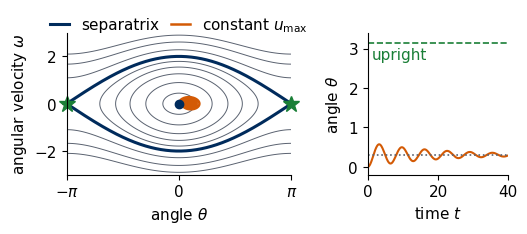

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(5.4, 2.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axs[0]
th_ = np.linspace(-np.pi, np.pi, 401); om_ = np.linspace(-3, 3, 301)
TH_, OM_ = np.meshgrid(th_, om_)
EE = 0.5 * OM_**2 + W0**2 * (1 - np.cos(TH_))
ax.contour(TH_, OM_, EE, levels=[0.1, 0.4, 0.8, 1.2, 1.6, 2.6, 3.4, 4.2], colors=UJGray, linewidths=0.7)
for sgn in (1, -1):
    ax.plot(th_, sgn * 2 * W0 * np.cos(th_ / 2), color=UJNavy, lw=2.2, label="separatrix" if sgn == 1 else None)
ax.plot(xs_const[:, 0], xs_const[:, 1], color=DSOrange, lw=1.8, label=r"constant $u_{\max}$")
ax.plot([0], [0], "o", color=UJNavy, ms=6)
ax.plot([-np.pi, np.pi], [0, 0], "*", color=UJGreen, ms=12, clip_on=False)
ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-3, 3)
ax.set_xticks([-np.pi, 0, np.pi]); ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
ax.set_xlabel(r"angle $\theta$"); ax.set_ylabel(r"angular velocity $\omega$")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.22), ncol=2, handlelength=1.2, columnspacing=0.8)
ax = axs[1]
t_ = np.arange(len(xs_const)) * DT
ax.plot(t_, xs_const[:, 0], color=DSOrange)
ax.axhline(np.pi, color=UJGreen, ls="--", lw=1.2); ax.text(1, np.pi - 0.4, "upright", color=UJGreen)
ax.axhline(np.arcsin(UMAX), color=UJGray, ls=":", lw=1.2)
ax.set_xlabel(r"time $t$"); ax.set_ylabel(r"angle $\theta$"); ax.set_ylim(-0.2, 3.4); ax.set_xlim(0, 40)
fig.tight_layout(); save(fig, "fig_lab056_phase_portrait"); plt.show()

In the left panel the grey curves are orbits of constant energy (2) of the pendulum without friction and drive, the thick curves the separatrix $E=E_{\rm s}$, the dot the hanging and the stars the upright position (the points $\theta=-\pi$ and $\theta=\pi$ are the same configuration). The orange curve is the damped motion (1) from rest with the constant torque $u_{\max}$. The right panel shows its angle $\theta(t)$ against the upright angle $\pi$ (dashed) and the shifted equilibrium $\arcsin u_{\max}$ (dotted).

Pumping in phase with the motion works like pushing a child on a swing, which is an analogy for the same equation (3). At each swing the motor pushes along the motion, the energy grows by $u_{\max}$ times the angle travelled, and the amplitude increases until the pendulum passes over the top. For small amplitudes $A$ the energy is $E\approx A^2/2$, a half swing from $-A$ to $A$ adds $\Delta E\approx2u_{\max}A$, and therefore the amplitude grows by about $2u_{\max}=0.6$ per half swing. This estimate neglects friction and the anharmonicity, and it predicts that the swing-up takes roughly five half swings.

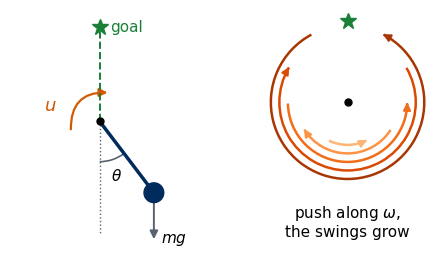

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(5.4, 2.7))
ax = axs[0]; ax.set_aspect("equal"); ax.axis("off")
th0 = 0.65; bob = np.array([np.sin(th0), -np.cos(th0)])
ax.plot([0, 0], [0, -1.25], color=UJGray, ls=":", lw=1)
ax.plot([0, 0], [0, 1.05], color=UJGreen, ls="--", lw=1.4); ax.plot(0, 1.05, "*", color=UJGreen, ms=12)
ax.text(0.12, 1.0, "goal", color=UJGreen)
ax.plot([0, bob[0]], [0, bob[1]], color=UJNavy, lw=2.5); ax.add_patch(Circle(bob, 0.11, color=UJNavy, zorder=3))
ax.plot(0, 0, "o", color="k", ms=5, zorder=4)
ax.add_patch(Arc((0, 0), 0.9, 0.9, theta1=270, theta2=270 + np.degrees(th0), color=UJGray, lw=1.2))
ax.text(0.13, -0.66, r"$\theta$")
ax.add_patch(FancyArrowPatch(bob, bob + np.array([0, -0.55]), arrowstyle="-|>", mutation_scale=12, color=UJGray, lw=1.4))
ax.text(bob[0] + 0.08, bob[1] - 0.55, r"$mg$")
ax.add_patch(FancyArrowPatch((-0.32, -0.12), (0.12, 0.32), connectionstyle="arc3,rad=-0.55", arrowstyle="-|>",
                             mutation_scale=12, color=DSOrange, lw=1.6))
ax.text(-0.62, 0.12, r"$u$", color=DSOrange, fontsize=13)
ax.set_xlim(-1.0, 1.0); ax.set_ylim(-1.3, 1.25)
ax = axs[1]; ax.set_aspect("equal"); ax.axis("off")
amps = [0.45, 1.0, 1.55, 2.1, 2.65]
for k, A in enumerate(amps):
    r = 0.55 + 0.11 * k; c = mpl.colormaps["Oranges"](0.35 + 0.13 * k)
    t1, t2 = (270 - np.degrees(A), 270 + np.degrees(A))
    ax.add_patch(Arc((0, 0), 2 * r, 2 * r, theta1=t1, theta2=t2, color=c, lw=1.8))
    end = np.radians(t2 if k % 2 == 0 else t1); d = 1 if k % 2 == 0 else -1
    p = r * np.array([np.cos(end), np.sin(end)]); tang = d * np.array([-np.sin(end), np.cos(end)])
    ax.add_patch(FancyArrowPatch(p - 0.05 * tang, p + 0.05 * tang, arrowstyle="-|>", mutation_scale=11, color=c, lw=1.5))
ax.plot(0, 0, "o", color="k", ms=5); ax.plot(0, 1.05, "*", color=UJGreen, ms=12)
ax.text(0, -1.3, "push along $\\omega$,\nthe swings grow", ha="center", va="top")
ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.75, 1.2)
fig.tight_layout(); save(fig, "fig_lab056_sketch"); plt.show()

The left drawing defines the angle $\theta$ from the hanging position, the gravitational force $mg$ on the bob and the motor torque $u$ at the pivot, bounded by $u_{\max}$. The arcs on the right are successive half swings of growing amplitude, each drawn at a slightly larger radius for visibility, with the arrow giving the direction of motion and of the torque.

The classical solution of control theory uses equation (3) directly. Åström and Furuta [K. J. Åström and K. Furuta, Automatica **36**, 287 (2000), [doi:10.1016/S0005-1098(99)00140-5](https://doi.org/10.1016/S0005-1098(99)00140-5)] control the energy of a pendulum whose pivot is accelerated, and the same idea applied to a torque at the pivot gives the rule

$$ u=u_{\max}\,\operatorname{sign}\!\big[\omega\,(E_{\rm s}-E)\big], \tag{4}$$

which pushes along the motion while the energy is too low and against it while the energy is too high. At rest at the bottom $\omega=0$, and we then choose $u=+u_{\max}$ to start the motion. Rule (4) brings the energy to the separatrix, and the pendulum then approaches the top along the separatrix. Balancing the pendulum at the top is, in the work of Åström and Furuta, the task of a second, linear controller. We use rule (4) as the physical reference for the policies that value iteration finds below.

In [5]:
def energy_controller(x):
    # rule (4), with +u_max when omega = 0
    s = jnp.where(x[1] * (E_SEP - energy(x)) >= 0, 2, 0)
    return jnp.where(jnp.abs(E_SEP - energy(x)) < 1e-12, 1, s)

## The swing-up as a Markov decision process

A Markov decision process consists of states $s$, actions $a$, rewards $r$ and the dynamics $p(s',r\mid s,a)$, the probability that action $a$ in state $s$ leads to the state $s'$ with the reward $r$. The swing-up fits this frame once we fix four choices.

The state is the point $(\theta,\omega)$ of the phase plane, which by equation (1) determines the future motion for a given torque, so the process is Markov. The agent decides every $\Delta t=0.1$, a tenth of a radian of the small-oscillation phase, and holds the chosen torque until the next decision. The actions are the three torques $u\in\{-u_{\max},0,+u_{\max}\}$, labelled $a=0,1,2$. Three values suffice for a strategy of the type of rule (4) above, which uses only the extreme torques. The reward after each interval is the height of the bob above the pivot in units of $\ell$,

$$ r_{t+1}=-\cos\theta_{t+1}\in[-1,1], \tag{5}$$

which is $-1$ hanging and $+1$ upright. The same height reward is used for the swing-up task in [K. Doya, Neural Comput. **12**, 219 (2000), [doi:10.1162/089976600300015961](https://doi.org/10.1162/089976600300015961)], here with the angle measured from the hanging position. It says nothing about energy or pumping. Any strategy has to be found by the agent. The return $G_t=\sum_{k\ge0}\gamma^k r_{t+k+1}$ weighs a reward $k$ intervals ahead by $\gamma^k$. We take $\gamma=0.98$, so rewards about $1/(1-\gamma)=50$ intervals ahead, five time units, still count with weight $e^{-1}$. This horizon is shorter than one period $2\pi$ of the small oscillation, and we will vary $\gamma$ to see how much look-ahead the swing-up needs. The task is continuing. We evaluate each policy on the continuous dynamics over 40 time units from the hanging position.

The phase plane is a continuum, and value iteration and tabular Q-learning need a finite set of states. We cover the region $-\pi\le\theta<\pi$, $|\omega|\le3$ with a grid of $51\times51$ points. The angle is periodic, so the grid wraps around in $\theta$, and the grid points lie at $\theta_i=-\pi+2\pi(i+\tfrac12)/51$, which puts $\theta=0$ on a grid point and the upright position halfway between two. The velocity grid $\omega_j=-3+6j/50$ covers the separatrix, whose largest velocity is $2\omega_0$, with a margin. Each grid point is one state $s$, $2601$ states in total.

The transition probabilities come from the physics. From the grid point $s=(\theta_i,\omega_j)$ we integrate equation (1) over $\Delta t$ with the torque of action $a$ and land at a point $x'$ between four grid points. We assign the four neighbours the bilinear interpolation weights of $x'$ as probabilities,

$$ p(s'\mid s,a)=w_{s'}(x'),\qquad \sum_{s'}w_{s'}(x')=1, \tag{6}$$

Near $\theta=\pm\pi$ the four neighbours are compared after shifting angles by $2\pi$, which the code checks. The reward of the transition is the height (5) at the end point $x'$, a deterministic function $r(s,a)$. The discretisation turns the deterministic pendulum into a finite Markov decision process with stochastic transitions, whose randomness models the uncertainty of where in the cell the pendulum is. Grids with interpolation weights read as transition probabilities are a standard way to build a finite model of a continuous control problem [R. Munos and A. Moore, Mach. Learn. **49**, 291 (2002), [doi:10.1023/A:1017992615625](https://doi.org/10.1023/A:1017992615625)]. The velocity of an end point outside $|\omega|\le3$ is clipped to the edge of the grid. The trajectory cell below prints the largest $|\omega|$ of the evaluated motions, which stays inside this range.

In [6]:
GAMMA = 0.98
ACTS = jnp.array([-UMAX, 0.0, UMAX])          # torques of the actions a = 0, 1, 2
NT, NW, WMAX = 51, 51, 3.0
TH_GRID = -jnp.pi + 2 * jnp.pi * (jnp.arange(NT) + 0.5) / NT
W_GRID = jnp.linspace(-WMAX, WMAX, NW)
XS = jnp.stack(jnp.meshgrid(TH_GRID, W_GRID, indexing="ij"), -1).reshape(-1, 2)   # state s = i * NW + j
S = XS.shape[0]

def wrap(th):
    return (th + jnp.pi) % (2 * jnp.pi) - jnp.pi

def bilinear(x):
    # the four grid points around x and their bilinear weights, equation (6); theta wraps around
    ti = (wrap(x[..., 0]) + jnp.pi) / (2 * jnp.pi) * NT - 0.5
    i0 = jnp.floor(ti).astype(int); ft = ti - i0
    wi = jnp.clip((x[..., 1] + WMAX) / (2 * WMAX) * (NW - 1), 0, NW - 1)
    j0 = jnp.clip(jnp.floor(wi).astype(int), 0, NW - 2); fw = wi - j0
    i0m, i1 = i0 % NT, (i0 + 1) % NT
    idx = jnp.stack([i0m * NW + j0, i1 * NW + j0, i0m * NW + j0 + 1, i1 * NW + j0 + 1], -1)
    wts = jnp.stack([(1 - ft) * (1 - fw), ft * (1 - fw), (1 - ft) * fw, ft * fw], -1)
    return idx, wts

def cell(x):
    # nearest grid point of a phase-space point, the state that the agent sees
    i = jnp.round((wrap(x[..., 0]) + jnp.pi) / (2 * jnp.pi) * NT - 0.5).astype(int) % NT
    j = jnp.clip(jnp.round((x[..., 1] + WMAX) / (2 * WMAX) * (NW - 1)).astype(int), 0, NW - 1)
    return i * NW + j

X_END = jnp.stack([propagate(XS, u) for u in ACTS], 1)           # end points, shape (S, 3, 2)
IDX, WTS = bilinear(X_END)                                         # p(s'|s,a) as 4 neighbours and weights
R = -jnp.cos(X_END[..., 0])                                         # reward r(s,a), equation (5)

dth = jnp.sum(WTS * wrap(XS[IDX][..., 0] - X_END[..., 0][..., None]), -1)   # mean angle offset, wrapped
xe_mean_w = jnp.sum(WTS * XS[IDX][..., 1], -1)
inner = jnp.abs(X_END[..., 1]) < WMAX
S_HANG = int(cell(jnp.array([0.0, 0.0])))
print(f"{S} states, 3 actions, 4 successors each; rows of p sum to one within {float(jnp.abs(WTS.sum(-1) - 1).max()):.1e}")
print(f"largest local-chart coordinate error with velocity clipping inactive: "
      f"{float(jnp.where(inner, jnp.hypot(dth, xe_mean_w - X_END[..., 1]), 0).max()):.1e}")
print("hanging state: grid point", np.asarray(XS[S_HANG]))
NUMBERS.update(Gamma=GAMMA, NGrid=NT, NStates=S)
# A seam endpoint needs locally lifted angles, while its stored arithmetic mean is zero.
seam=jnp.array([jnp.pi,0.0]);seam_idx,seam_w=bilinear(seam)
stored=XS[seam_idx,0]
lifted=seam[0]+wrap(stored-seam[0])
assert np.isclose(float(jnp.sum(seam_w*lifted)),np.pi)
assert np.isclose(float(jnp.sum(seam_w*stored)),0.0)
print('Periodic-seam local-chart test passes')

2601 states, 3 actions, 4 successors each; rows of p sum to one within 1.1e-16
largest local-chart coordinate error with velocity clipping inactive: 2.0e-15
hanging state: grid point [ 0.00000000e+00 -5.55111512e-17]
Periodic-seam local-chart test passes


The rows of the transition matrix sum to one. The figure shows the construction for one grid point. The three arrows are the motions over $\Delta t$ under the three torques, and the circles on the grid points around the end point of $+u_{\max}$ have areas proportional to the probabilities $p(s'\mid s,a)$.

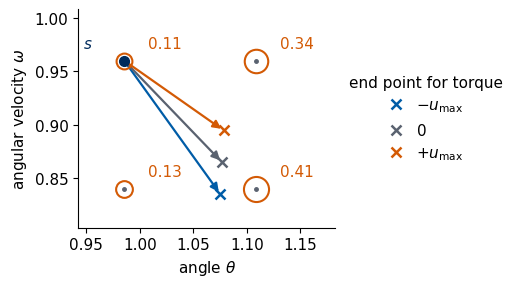

In [7]:
s_demo = int(cell(jnp.array([1.0, 1.0])))
x0 = np.asarray(XS[s_demo])
fig, ax = plt.subplots(figsize=(5.2, 3.0))
dth_, dw_ = 2 * np.pi / NT, 2 * WMAX / (NW - 1)
gi = np.arange(-2, 4); gj = np.arange(-2, 4)
GX, GY = np.meshgrid(x0[0] + gi * dth_, x0[1] + gj * dw_)
ax.plot(GX, GY, ".", color=UJGray, ms=5)
cols = [UJBlue, UJGray, DSOrange]; labs = [r"$-u_{\max}$", r"$0$", r"$+u_{\max}$"]
for a in range(3):
    xe = np.asarray(X_END[s_demo, a])
    ax.add_patch(FancyArrowPatch(x0, xe, arrowstyle="-|>", mutation_scale=12, color=cols[a], lw=1.6))
    ax.plot(*xe, "x", color=cols[a], ms=7, mew=1.8, label=labs[a])
for k in range(4):
    sp = int(IDX[s_demo, 2, k]); w = float(WTS[s_demo, 2, k]); p = np.asarray(XS[sp])
    ax.plot(*p, "o", ms=4 + 22 * np.sqrt(w), mfc="none", mec=DSOrange, mew=1.5)
    ax.text(p[0] + 0.022, p[1] + 0.012, f"{w:.2f}", color=DSOrange)
ax.plot(*x0, "o", color=UJNavy, ms=7); ax.text(x0[0] - 0.03, x0[1] + 0.012, r"$s$", color=UJNavy, ha="right")
ax.set_xlim(x0[0] - 0.35 * dth_, x0[0] + 1.6 * dth_); ax.set_ylim(x0[1] - 1.3 * dw_, x0[1] + 0.4 * dw_)
ax.set_aspect("equal")
ax.set_xlabel(r"angle $\theta$"); ax.set_ylabel(r"angular velocity $\omega$")
ax.legend(title="end point for torque", loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1)
fig.tight_layout(); save(fig, "fig_lab056_grid"); plt.show()

Grey dots are grid points of the phase plane, the navy dot is the state $s$, and the crosses are the end points $x'$ after $\Delta t$ for the three torques. The numbers give the probabilities $p(s'\mid s,a=+u_{\max})$ of the four grid points around the orange end point.

## Value iteration with the model

The optimal value $V_*(s)$ is the largest expected return from $s$ over all policies, and it obeys the Bellman optimality equation

$$ V_*(s)=\max_a\Big[r(s,a)+\gamma\sum_{s'}p(s'\mid s,a)\,V_*(s')\Big],\qquad Q_*(s,a)=r(s,a)+\gamma\sum_{s'}p(s'\mid s,a)\,V_*(s'). \tag{7}$$

Value iteration applies the right-hand side $\mathcal T$ repeatedly, $V_{k+1}=\mathcal TV_k$ from $V_0=0$. The map $\mathcal T$ contracts distances in the maximum norm by at least $\gamma$, so $\|V_k-V_*\|_\infty\le\gamma^k\|V_0-V_*\|_\infty$ [Sutton and Barto, Sec. 4.4]. The optimal policy picks the best action in every state, $\pi_*(s)=\arg\max_aQ_*(s,a)$. The next cell runs value iteration far beyond convergence to obtain the reference $V_*$ and then records the error of every iterate.

value iteration, 4000 sweeps: 1.2 s; Bellman residual 0.0e+00
|V_0 - V_*| = 48.74; error after 100, 500, 1000 sweeps: 6.15e+00, 1.86e-03, 7.61e-08; measured rate per sweep 0.9800, gamma = 0.98
V_* at the hanging state -32.10, largest V_* 48.74, upright forever would give 1/(1-gamma) = 50


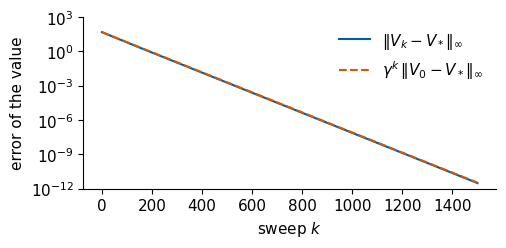

In [8]:
def q_from_v(V, gamma):
    # right-hand side of equation (7) for all states and actions
    return R + gamma * jnp.sum(WTS * V[IDX], -1)

@partial(jax.jit, static_argnums=(1,))
def value_iteration(gamma, n):
    return lax.fori_loop(0, n, lambda k, V: q_from_v(V, gamma).max(1), jnp.zeros(S))

@partial(jax.jit, static_argnums=(2,))
def vi_errors(gamma, V_ref, n):
    def body(V, _):
        Vn = q_from_v(V, gamma).max(1); return Vn, jnp.abs(Vn - V_ref).max()
    return lax.scan(body, jnp.zeros(S), None, n)[1]

t0 = time.time()
V_star = value_iteration(GAMMA, 4000)
Q_star = q_from_v(V_star, GAMMA)
PI_STAR = Q_star.argmax(1)
errs = np.asarray(vi_errors(GAMMA, V_star, 1500))
k_ = np.arange(1, len(errs) + 1)
rate = (errs[1000] / errs[500])**(1 / 500)
print(f"value iteration, 4000 sweeps: {time.time() - t0:.1f} s; Bellman residual {float(jnp.abs(Q_star.max(1) - V_star).max()):.1e}")
print(f"|V_0 - V_*| = {float(jnp.abs(V_star).max()):.2f}; error after 100, 500, 1000 sweeps: "
      f"{errs[99]:.2e}, {errs[499]:.2e}, {errs[999]:.2e}; measured rate per sweep {rate:.4f}, gamma = {GAMMA}")
print(f"V_* at the hanging state {float(V_star[S_HANG]):.2f}, largest V_* {float(V_star.max()):.2f}, "
      f"upright forever would give 1/(1-gamma) = {1/(1-GAMMA):.0f}")
NUMBERS.update(ViRate=round(float(rate), 4), VstarHang=round(float(V_star[S_HANG]), 2), VstarMax=round(float(V_star.max()), 2))

fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.semilogy(k_, errs, color=UJBlue, label=r"$\|V_k-V_*\|_\infty$")
ax.semilogy(k_, GAMMA**k_ * float(jnp.abs(V_star).max()), color=DSOrange, ls="--", label=r"$\gamma^k\,\|V_0-V_*\|_\infty$")
ax.set_xlabel(r"sweep $k$"); ax.set_ylabel("error of the value"); ax.set_ylim(1e-12, 1e3); ax.legend()
fig.tight_layout(); save(fig, "fig_lab056_vi_convergence"); plt.show()

The error of value iteration (blue) runs just below the contraction bound $\gamma^k\|V_0-V_*\|_\infty$ (dashed), for example 6.15 against 6.46 after 100 sweeps, and decreases by the factor $0.980$ per sweep, the discount factor itself. The error comes this close to the bound because of the states near the upright position. There the optimal policy collects a reward close to one at every step, so the $k$-th iterate is approximately the partial sum $V_*(1-\gamma^k)$ and its error approximately $\gamma^kV_*$. For the largest optimal value, $48.74=\|V_0-V_*\|_\infty$, this is the bound itself. Holding the pendulum exactly upright forever would give $1/(1-\gamma)=50$. From the hanging position $V_*=-32.10$, because a swing-up from the bottom spends its first part below the pivot, where the reward is negative.

The value is the expected discounted height, and the policy is easier to read, the torque that $\pi_*$ chooses at each point of the phase plane. The map below colours every grid point by its optimal action.

In [9]:
ACT_CMAP = ListedColormap([UJSky, "#e9ecef", "#f2a35e"])
TH_EDGES = np.linspace(-np.pi, np.pi, NT + 1)
W_EDGES = np.linspace(-WMAX - WMAX / (NW - 1), WMAX + WMAX / (NW - 1), NW + 1)

def draw_policy(ax, pol, traj=None, legend=True):
    # action of every grid point; theta is the horizontal axis
    ax.pcolormesh(TH_EDGES, W_EDGES, np.asarray(pol).reshape(NT, NW).T, cmap=ACT_CMAP, vmin=-0.5, vmax=2.5,
                  rasterized=True)
    th = np.linspace(-np.pi, np.pi, 300)
    for sgn in (1, -1):
        ax.plot(th, sgn * 2 * W0 * np.cos(th / 2), color=UJNavy, lw=1.6)
    if traj is not None:
        tw = np.asarray(wrap(traj[:, 0])); jump = np.abs(np.diff(tw)) > np.pi
        tw_plot, w_plot = tw.copy(), np.asarray(traj[:, 1]).copy()
        tw_plot[1:][jump] = np.nan
        ax.plot(tw_plot, w_plot, color="k", lw=1.1)
        ax.plot(tw[0], w_plot[0], "o", color="k", ms=4)
    ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-WMAX, WMAX)
    ax.set_xticks([-np.pi, 0, np.pi]); ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
    ax.set_xlabel(r"angle $\theta$"); ax.set_ylabel(r"angular velocity $\omega$")
    if legend:
        hs = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (UJSky, "#e9ecef", "#f2a35e")]
        ax.legend(hs, [r"$-u_{\max}$", "0", r"$+u_{\max}$"], loc="center left", bbox_to_anchor=(1.0, 0.5),
                  title="torque", handlelength=1)

E_GRID = np.asarray(energy(XS)); W_ = np.asarray(XS[:, 1])
inside = (E_GRID < E_SEP) & (W_ != 0)
pump = np.where(W_ > 0, 2, 0)
pol = np.asarray(PI_STAR)
frac_pump = np.mean(pol[inside] == pump[inside])
frac_zero = np.mean(pol == 1)
print(f"inside the separatrix (omega != 0): optimal torque has the sign of omega in {100*frac_pump:.1f}% of the grid points")
print(f"zero torque is optimal in {100*frac_zero:.1f}% of all grid points")
NUMBERS.update(PumpFrac=round(100 * frac_pump, 1), ZeroFrac=round(100 * frac_zero, 1))

inside the separatrix (omega != 0): optimal torque has the sign of omega in 93.4% of the grid points
zero torque is optimal in 0.8% of all grid points


optimal          first within 45 deg of upright at t =  13.6, stays there from t =  19.4, fraction of the last 10 time units upright 1.00, largest height 1.000
greedy           first within 45 deg of upright at t =   inf, stays there from t =   inf, fraction of the last 10 time units upright 0.00, largest height -0.841
energy rule (4)  first within 45 deg of upright at t =  14.2, stays there from t =  36.8, fraction of the last 10 time units upright 0.67, largest height 1.000
optimal swing-up: 5 reversals of the motion before the top
largest |omega| along the three trajectories 2.07, velocity grid edge 3.0


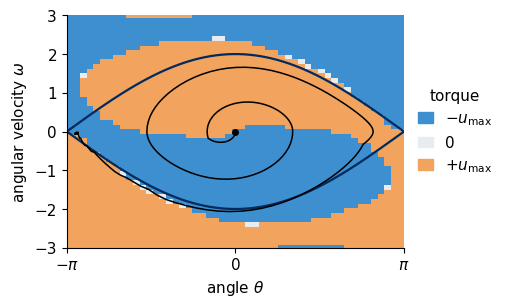

In [10]:
@partial(jax.jit, static_argnums=(2,))
def rollout_table(table, x0, n):
    # the continuous pendulum (1) driven by a tabular policy; the agent sees the nearest grid point
    def body(x, _):
        a = table[cell(x)]; return propagate(x, ACTS[a]), (x, a)
    xT, (xs, acts) = lax.scan(body, x0, None, n)
    return jnp.concatenate([xs, xT[None]]), acts

@partial(jax.jit, static_argnums=(1,))
def rollout_rule(x0, n):
    # the continuous pendulum driven by the energy rule (4)
    def body(x, _):
        a = energy_controller(x); return propagate(x, ACTS[a]), (x, a)
    xT, (xs, acts) = lax.scan(body, x0, None, n)
    return jnp.concatenate([xs, xT[None]]), acts

def upright(xs):
    # within 45 degrees of the upright position
    return np.cos(np.asarray(xs)[:, 0]) < -np.cos(np.pi / 4)

def summary(xs):
    # first time within 45 degrees of upright, time from which it stays there until the end,
    # fraction of the last 10 time units upright, largest height
    up = upright(xs); first = np.argmax(up) * DT if up.any() else np.inf
    stay = (len(up) - np.argmax(~up[::-1])) * DT if up[-1] else np.inf
    return first, stay, up[-100:].mean(), float(np.max(-np.cos(np.asarray(xs)[:, 0])))

N_EVAL = 400                                   # 40 time units
X_HANG = jnp.array([0.0, 0.0])
traj_opt, act_opt = rollout_table(PI_STAR, X_HANG, N_EVAL)
PI_GREEDY = R.argmax(1)                        # gamma = 0, the largest immediate reward
traj_gr, act_gr = rollout_table(PI_GREEDY, X_HANG, N_EVAL)
traj_en, act_en = rollout_rule(X_HANG, N_EVAL)
for nm, tr in (("optimal", traj_opt), ("greedy", traj_gr), ("energy rule (4)", traj_en)):
    f, stay, st, hmax = summary(tr)
    print(f"{nm:16s} first within 45 deg of upright at t = {f:5.1f}, stays there from t = {stay:5.1f}, "
          f"fraction of the last 10 time units upright {st:.2f}, largest height {hmax:.3f}")
om_ = np.asarray(traj_opt[:-1, 1]); f_opt = summary(traj_opt)[1]
pre = np.arange(len(om_)) * DT < f_opt
n_rev = int(np.sum(np.diff(np.sign(om_[pre])) != 0))
print(f"optimal swing-up: {n_rev} reversals of the motion before the top")
wmax = max(float(np.abs(np.asarray(t[:, 1])).max()) for t in (traj_opt, traj_gr, traj_en))
print(f"largest |omega| along the three trajectories {wmax:.2f}, velocity grid edge {WMAX}")
assert wmax < WMAX
NUMBERS.update(TfirstOpt=round(summary(traj_opt)[0], 1), TupOpt=round(f_opt, 1), TfirstEnergy=round(summary(traj_en)[0], 1),
               StayEnergy=round(summary(traj_en)[2], 2), HmaxGreedy=round(summary(traj_gr)[3], 2), NRevOpt=n_rev,
               ThMaxGreedyDeg=round(float(np.degrees(np.abs(np.asarray(traj_gr[:, 0])).max())), 1))

fig, ax = plt.subplots(figsize=(5.2, 3.2))
draw_policy(ax, PI_STAR, traj_opt[:int(f_opt / DT) + 30])
fig.tight_layout(); save(fig, "fig_lab056_policy"); plt.show()

Each grid point is coloured by the optimal torque $\pi_*(s)$, the navy curves are the separatrix, and the black curve is the swing-up of the continuous pendulum (1) from the hanging position (dot) under this policy, followed until shortly after it settles upright.

Inside the separatrix the optimal torque has the sign of $\omega$ in $93.4\%$ of the grid points. The upper half of the region inside the separatrix, where the pendulum moves to positive angles, is mostly orange and the lower half mostly blue. This is the pumping rule of equation (3), found by value iteration from the height reward (5) alone, without any notion of energy. The exceptions lie along the separatrix and near the top, where the policy pushes against the motion so that the pendulum comes to rest upright. Well outside the separatrix, where the energy is too high, the torque opposes the motion and removes energy. Zero torque is optimal in only $0.8\%$ of the grid points, so the policy is almost bang-bang, like rule (4). The black trajectory spirals outwards from the bottom in growing loops. Its first approach to the top at $t=13.6$ has too little energy, the pendulum swings back through the bottom and reaches the top from the other side, where it stays from $t=19.4$ on, after five reversals of the motion.

The time series show the same swing-up. The torque switches with the sign of the angular velocity, the energy (2) grows swing by swing to the separatrix value $E_{\rm s}$, and the pendulum then stays upright, held by fast switching of the torque around the unstable equilibrium.

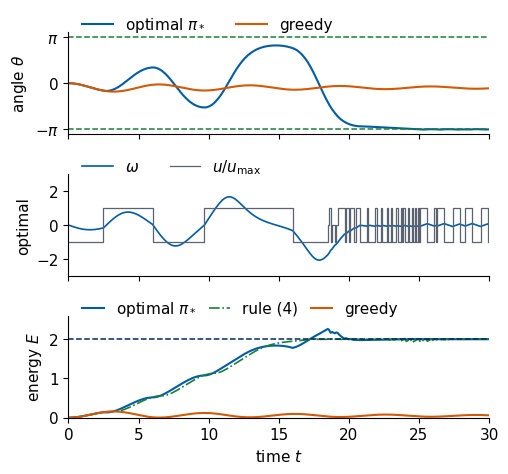

In [11]:
t_ = np.arange(N_EVAL + 1) * DT
fig, axs = plt.subplots(3, 1, figsize=(5.2, 4.9), sharex=True)
ax = axs[0]
ax.plot(t_, np.asarray(traj_opt[:, 0]), color=UJBlue, label=r"optimal $\pi_*$")
ax.plot(t_, np.asarray(traj_gr[:, 0]), color=DSOrange, label="greedy")
ax.axhline(np.pi, color=UJGreen, ls="--", lw=1.1); ax.axhline(-np.pi, color=UJGreen, ls="--", lw=1.1)
ax.set_ylabel(r"angle $\theta$"); ax.set_yticks([-np.pi, 0, np.pi]); ax.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])
ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0, 1.3))
ax = axs[1]
ax.plot(t_, np.asarray(traj_opt[:, 1]), color=UJBlue, lw=1.2, label=r"$\omega$")
ax.step(t_[:-1], np.asarray(ACTS[act_opt]) / UMAX, where="post", color=UJGray, lw=0.9, label=r"$u/u_{\max}$")
ax.set_ylabel("optimal"); ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0, 1.3)); ax.set_ylim(-3, 3)
ax = axs[2]
ax.plot(t_, np.asarray(energy(traj_opt)), color=UJBlue, label=r"optimal $\pi_*$")
ax.plot(t_, np.asarray(energy(traj_en)), color=UJGreen, lw=1.2, ls="-.", label="rule (4)")
ax.plot(t_, np.asarray(energy(traj_gr)), color=DSOrange, label="greedy")
ax.axhline(E_SEP, color=UJNavy, ls="--", lw=1.1)
ax.set_ylabel(r"energy $E$"); ax.set_xlabel(r"time $t$"); ax.set_xlim(0, 30); ax.set_ylim(0, 2.6)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.3), handlelength=1.4, ncol=3, columnspacing=0.8)
fig.tight_layout(h_pad=0.6); save(fig, "fig_lab056_swingup"); plt.show()

Top, the angle $\theta(t)$ from the hanging position at rest under the optimal policy (blue) and under the greedy policy (orange), with the upright angles $\pm\pi$ dashed. Middle, the angular velocity $\omega(t)$ and the torque $u(t)/u_{\max}$ of the optimal policy. Bottom, the energy (2) under the three policies, with the separatrix energy $E_{\rm s}$ dashed, where rule (4) is the energy controller.

## Greedy against optimal

The greedy policy chooses the action with the largest immediate reward, $\arg\max_ar(s,a)$, which is the optimal policy for $\gamma=0$. It pushes towards the top in every state, and the pendulum stays near the bottom as under the constant torque of the first section, with the largest bob height $-0.84\,\ell$. The optimal policy reverses the torque at every turning point and lets the pendulum fall back from each swing. This is the delayed reward. Moving away from the goal costs height now and pays later, and only a policy that looks ahead accepts the cost. The energy rule (4) pumps as fast as the optimal policy, and its energy curve nearly coincides with the optimal one. It first comes within 45 degrees of the top at $t=14.2$, but it holds the pendulum there only in the fraction $0.67$ of the last ten time units, because it drives the energy to the separatrix and contains no balancing.

The strip of snapshots shows the two behaviours as the pendulum would look on a video, every three time units.

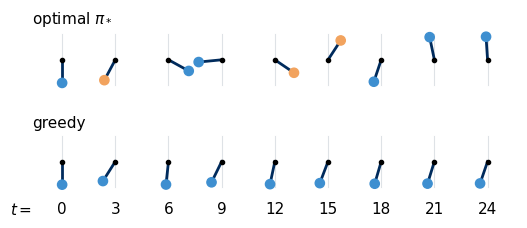

In [12]:
def snapshot_strip(ax, traj, acts, times, colour):
    # pendulum drawn at the given times, side by side; the bob colour gives the torque
    for k, t in enumerate(times):
        n = int(round(t / DT)); th = float(traj[n, 0]); x0 = 2.3 * k
        bob = (x0 + np.sin(th), -np.cos(th))
        ax.plot([x0, x0], [-1.1, 1.1], color="#dee2e6", lw=0.8, zorder=0)
        ax.plot([x0, bob[0]], [0, bob[1]], color=colour, lw=2)
        a = int(acts[min(n, len(acts) - 1)])
        ax.add_patch(Circle(bob, 0.2, color=(UJSky, UJGray, "#f2a35e")[a], zorder=3))
        ax.plot(x0, 0, "o", color="k", ms=3, zorder=4)
    ax.set_xlim(-1.3, 2.3 * (len(times) - 1) + 1.3); ax.set_ylim(-1.35, 1.35); ax.set_aspect("equal"); ax.axis("off")

times = np.arange(0, 25, 3.0)
fig, axs = plt.subplots(2, 1, figsize=(5.4, 2.6))
snapshot_strip(axs[0], np.asarray(traj_opt), np.asarray(act_opt), times, UJNavy)
snapshot_strip(axs[1], np.asarray(traj_gr), np.asarray(act_gr), times, UJNavy)
axs[0].set_title(r"optimal $\pi_*$", loc="left", pad=2); axs[1].set_title("greedy", loc="left", pad=2)
for k, t in enumerate(times):
    axs[1].text(2.3 * k, -1.75, f"{t:.0f}", ha="center", va="top")
axs[1].text(-1.3, -1.75, r"$t=$", ha="right", va="top")
fig.tight_layout(h_pad=0.2); save(fig, "fig_lab056_snapshots"); plt.show()

Each row draws the pendulum at the times $t=0,3,\dots,24$ under the optimal (top) and the greedy policy (bottom), with the bob coloured by the torque at that moment (orange $+u_{\max}$, blue $-u_{\max}$, grey zero). The optimal pendulum swings to alternating sides with growing amplitude and stands upright at $t=21$ and $t=24$, while the greedy one leans slightly to one side the whole time.

## How far the agent has to look ahead

The discount factor sets how far ahead rewards count, about $1/(1-\gamma)$ decisions or $\Delta t/(1-\gamma)$ time units. We repeat value iteration for several values of $\gamma$ and run each optimal policy from the hanging position. A policy succeeds if the pendulum is within 45 degrees of upright during the whole of the last ten of 40 time units.

gamma = 0.00  horizon   0.1 time units  largest height -0.841  fraction upright in the last 10 time units 0.00
gamma = 0.50  horizon   0.2 time units  largest height -0.841  fraction upright in the last 10 time units 0.00
gamma = 0.60  horizon   0.2 time units  largest height -0.503  fraction upright in the last 10 time units 0.00
gamma = 0.70  horizon   0.3 time units  largest height  0.013  fraction upright in the last 10 time units 0.00
gamma = 0.80  horizon   0.5 time units  largest height  0.902  fraction upright in the last 10 time units 0.38
gamma = 0.85  horizon   0.7 time units  largest height  1.000  fraction upright in the last 10 time units 1.00
gamma = 0.90  horizon   1.0 time units  largest height  1.000  fraction upright in the last 10 time units 1.00
gamma = 0.95  horizon   2.0 time units  largest height  1.000  fraction upright in the last 10 time units 1.00
gamma = 0.98  horizon   5.0 time units  largest height  1.000  fraction upright in the last 10 time units 1.00
g

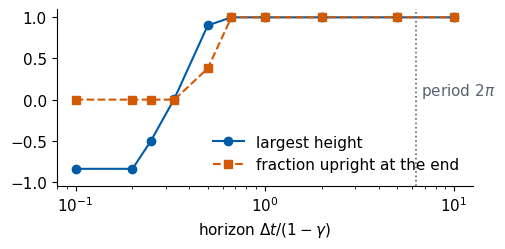

In [13]:
GAMMAS = [0.0, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98, 0.99]
hz, hmax_g, stay_g = [], [], []
for g in GAMMAS:
    Vg = value_iteration(g, 4000)
    tr, _ = rollout_table(q_from_v(Vg, g).argmax(1), X_HANG, N_EVAL)
    f, stay, st, hm = summary(tr)
    hz.append(DT / (1 - g)); hmax_g.append(hm); stay_g.append(st)
    print(f"gamma = {g:4.2f}  horizon {DT/(1-g):5.1f} time units  largest height {hm:6.3f}  "
          f"fraction upright in the last 10 time units {st:.2f}")
ok = [g for g, st in zip(GAMMAS, stay_g) if st == 1.0]
NUMBERS.update(GammaMinSwing=min(ok), HorizonMinSwing=round(DT / (1 - min(ok)), 1))

fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.semilogx(hz, hmax_g, "o-", color=UJBlue, label="largest height")
ax.semilogx(hz, stay_g, "s--", color=DSOrange, label="fraction upright at the end")
ax.axvline(2 * np.pi, color=UJGray, ls=":", lw=1.2); ax.text(2 * np.pi * 1.07, 0.05, r"period $2\pi$", color=UJGray)
ax.set_xlabel(r"horizon $\Delta t/(1-\gamma)$"); ax.set_ylim(-1.05, 1.1)
ax.legend(loc="lower right")
fig.tight_layout(); save(fig, "fig_lab056_horizon"); plt.show()

For each discount factor the blue points give the largest height $-\cos\theta$ that the optimal policy of that $\gamma$ reaches from the hanging position within 40 time units, and the orange squares the fraction of the last ten time units spent within 45 degrees of upright. The horizontal axis is the look-ahead time $\Delta t/(1-\gamma)$, and the dotted line marks the period of small oscillations.

The policies of $\gamma=0$, $0.5$ and $0.6$ never lift the bob above the pivot. For $\gamma=0.7$ and $0.8$ the pendulum gets higher, and for $\gamma=0.8$ it spends only the fraction $0.38$ of the last ten time units upright, while for every tested value from $\gamma=0.85$ on, a look-ahead of $0.7$ time units, the optimal policy swings the pendulum up and holds it. These statements refer to the single hanging start, the $51\times51$ grid and the decision interval $\Delta t=0.1$. This look-ahead is about a ninth of the period $2\pi$, much shorter than the whole swing-up of about twenty time units. A push along the motion pays off within the same half swing, as the pendulum climbs higher before it turns, and the swing-up is assembled from these short-range gains, even though the pendulum moves away from the goal during half of each swing. With a shorter look-ahead the policy weighs mainly the immediate height.


The planning route ends here. The optional [full pendulum notebook](lab-056-pendulum-swing-up.ipynb) contains the extended Q-learning experiment, whose complete four-seed training run was executed on.

## Student calculations
Derive the energy-change equation and explain the sign of the pumping torque. Compare the immediate-reward policy with the value-iteration policy on the same continuous dynamics. Explain why the finite grid changes the model and why model-based optimality on that grid requires independent trajectory evaluation.